In [28]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [29]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [30]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [33]:
from sklearn.datasets import load_iris

# Load iris dataset from sklearn
iris = load_iris(as_frame=True)
df = iris.frame

In [34]:
df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
5,5.4,3.9,1.7,0.4,0
6,4.6,3.4,1.4,0.3,0
7,5.0,3.4,1.5,0.2,0
8,4.4,2.9,1.4,0.2,0
9,4.9,3.1,1.5,0.1,0


In [35]:
df.shape

(150, 5)

In [36]:
df.head(150)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [37]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [38]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [40]:
df["target"].value_counts().rename_axis(None)

0    50
1    50
2    50
Name: count, dtype: int64

In [41]:
df["target"].value_counts()

target
0    50
1    50
2    50
Name: count, dtype: int64

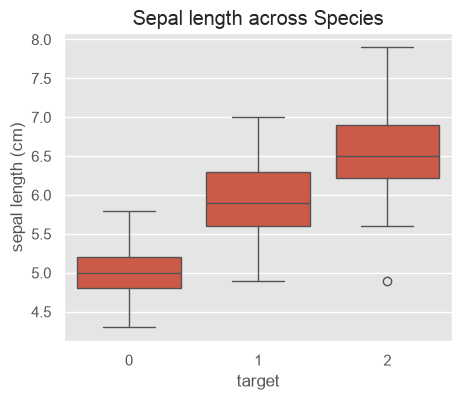

In [42]:
plt.style.use("ggplot")
plt.figure(figsize=(5,4))
sns.boxplot(data=df, x= "target", y= "sepal length (cm)")
plt.title("Sepal length across Species")
plt.show()

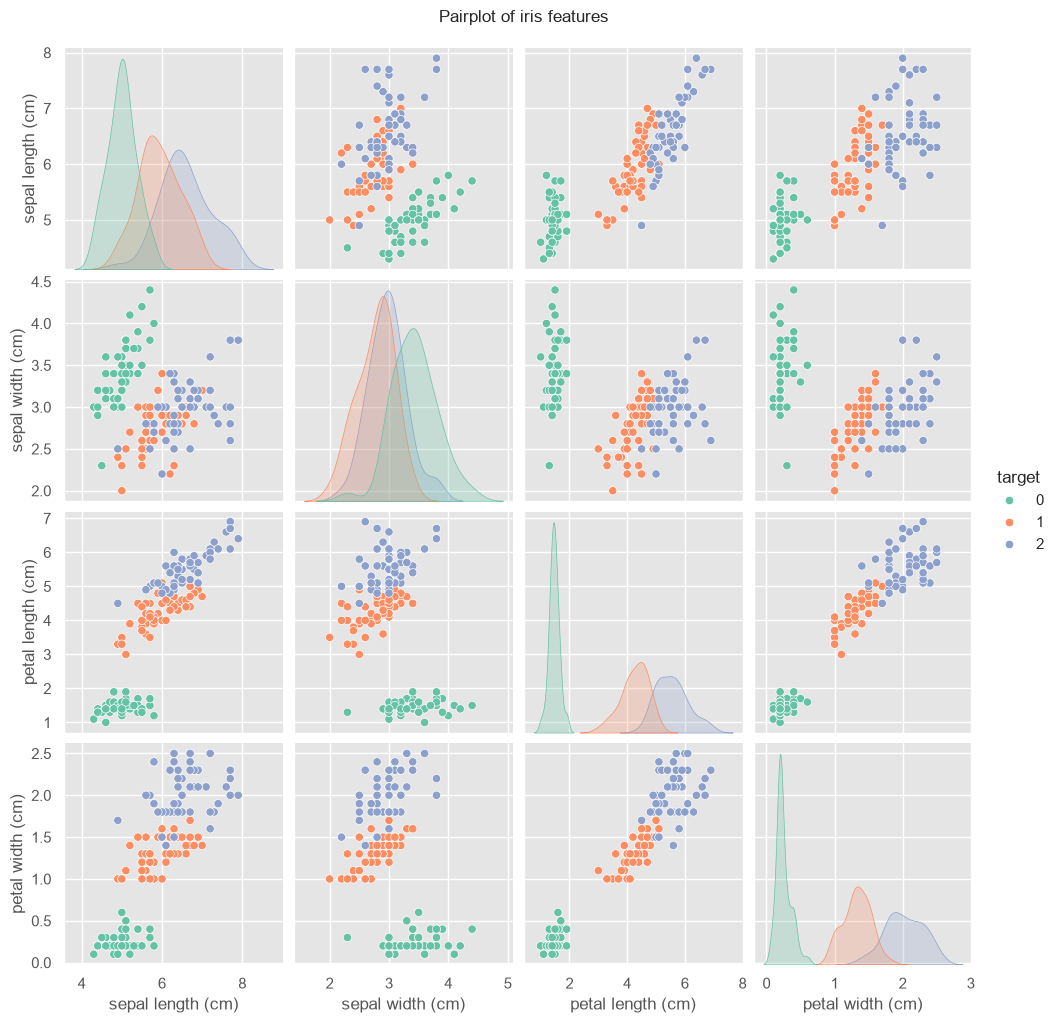

In [52]:
sns.pairplot(df, hue = "target", palette = "Set2")
plt.suptitle("Pairplot of iris features", y= 1.02)
plt.show()

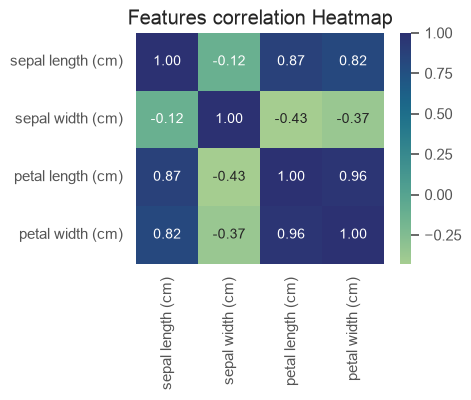

In [57]:
plt.figure(figsize= (4,3))
heatmap_df = df.drop(columns = ["target"])
sns.heatmap(heatmap_df.corr(), annot = True, cmap = "crest", fmt = ".2f")
plt.title("Features correlation Heatmap")
plt.show()


In [62]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [64]:
X = df.drop(columns = ["target"])
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

model = DecisionTreeClassifier(random_state = 42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [66]:
print(f"Accuracy Score: {accuracy_score(y_test, y_pred) * 100: .2f}%")

Accuracy Score:  93.33%


In [68]:
print("Classification Report:\n", classification_report(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



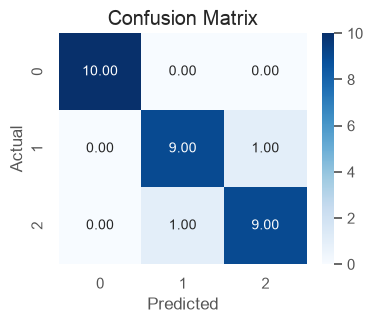

In [69]:
plt.figure(figsize = (4,3))
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, fmt = ".2f",
            xticklabels = model.classes_, yticklabels = model.classes_, cmap = "Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()